# 09 — Object Detection Model Comparison

**Project:** Privacy-Preserving Edge AI Framework for Intelligent Transportation  
**Dataset:** India Driving Dataset (IDD Detection)

## Models
- YOLOv8n
- YOLO11n
- YOLO11s
- MobileNetV2-based custom grid detector

## Comparison criteria
- Validation precision and recall
- mAP@50 and mAP@50–95
- Training duration, if recorded
- Checkpoint size
- Inference speed, if benchmark results exist

Only metrics produced by valid evaluation procedures will be compared. Missing or incompatible metrics will be marked N/A. Test images without annotations will not be used to calculate accuracy or mAP.

In [1]:
# CELL 2: Imports and comparison paths

from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path("/workspace/ITS_Project")
TRAINING_RESULTS = PROJECT / "results" / "training"
CHECKPOINTS = PROJECT / "checkpoints"
COMPARISON_DIR = PROJECT / "results" / "model_comparison"

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

print("Project:", PROJECT)
print("Training results:", TRAINING_RESULTS)
print("Checkpoints:", CHECKPOINTS)
print("Comparison outputs:", COMPARISON_DIR)

Project: /workspace/ITS_Project
Training results: /workspace/ITS_Project/results/training
Checkpoints: /workspace/ITS_Project/checkpoints
Comparison outputs: /workspace/ITS_Project/results/model_comparison


In [9]:
# CELL 3: Define the known metric file locations

METRIC_FILES = {
    "YOLOv8n": TRAINING_RESULTS / "yolov8n" / "validation_metrics_full.json",
    "YOLO11n": TRAINING_RESULTS / "yolo11n" / "validation_metrics_full.json",
    "YOLO11s": TRAINING_RESULTS / "yolo11s" / "validation_metrics_full.json",
    "MobileNetV2": TRAINING_RESULTS / "mobilenetv2" / "validation_metrics.json",
}

for model_name, path in METRIC_FILES.items():
    print(f"{model_name}: {'FOUND' if path.is_file() else 'NOT FOUND'}")
    print(" ", path)

YOLOv8n: FOUND
  /workspace/ITS_Project/results/training/yolov8n/validation_metrics_full.json
YOLO11n: FOUND
  /workspace/ITS_Project/results/training/yolo11n/validation_metrics_full.json
YOLO11s: FOUND
  /workspace/ITS_Project/results/training/yolo11s/validation_metrics_full.json
MobileNetV2: FOUND
  /workspace/ITS_Project/results/training/mobilenetv2/validation_metrics.json


In [10]:
# CELL 4: Load available metrics without assuming every model succeeded

metric_records = []

for model_name, path in METRIC_FILES.items():
    if not path.is_file():
        print(f"Skipping unavailable metrics: {model_name}")
        continue

    try:
        with open(path, "r") as f:
            record = json.load(f)

        metric_records.append({
            "Model": model_name,
            "Precision": record.get("precision"),
            "Recall": record.get("recall"),
            "mAP50": record.get("mAP50"),
            "mAP50-95": record.get("mAP50_95"),
            "Training images": record.get("training_images"),
            "Validation images": record.get("validation_images"),
            "Training duration (seconds)": record.get("training_duration_seconds"),
        })

        print(f"Loaded metrics: {model_name}")

    except (json.JSONDecodeError, OSError) as error:
        print(f"Could not read {model_name}: {error}")

metrics_df = pd.DataFrame(metric_records)
display(metrics_df)

Loaded metrics: YOLOv8n
Loaded metrics: YOLO11n
Loaded metrics: YOLO11s
Loaded metrics: MobileNetV2


,Model,Precision,Recall,mAP50,mAP50-95,Training images,Validation images,Training duration (seconds)
0,YOLOv8n,0.719140,0.293732,0.325049,0.205821,NaN,NaN,None
1,YOLO11n,0.713988,0.287399,0.318175,0.202377,31569.0,10225.0,None
2,YOLO11s,0.698187,0.337988,0.376025,0.241272,31569.0,10225.0,None
3,MobileNetV2,0.256195,0.121388,NaN,NaN,31569.0,10225.0,None


In [11]:
# CELL 5: Normalize metric values and save the initial comparison table

if metrics_df.empty:
    print("No metric files were loaded.")
    print("Check the printed paths and verify that previous notebooks saved their JSON files.")
else:
    metric_columns = ["Precision", "Recall", "mAP50", "mAP50-95"]

    for column in metric_columns:
        metrics_df[column] = pd.to_numeric(
            metrics_df[column], errors="coerce"
        )

    metrics_df["Metrics available"] = metrics_df[metric_columns].notna().sum(axis=1)

    initial_table = COMPARISON_DIR / "model_comparison_initial.csv"
    metrics_df.to_csv(initial_table, index=False)

    print("Saved initial comparison table:", initial_table)
    display(metrics_df)


Saved initial comparison table: /workspace/ITS_Project/results/model_comparison/model_comparison_initial.csv


,Model,Precision,Recall,mAP50,mAP50-95,Training images,Validation images,Training duration (seconds),Metrics available
0,YOLOv8n,0.719140,0.293732,0.325049,0.205821,NaN,NaN,None,4
1,YOLO11n,0.713988,0.287399,0.318175,0.202377,31569.0,10225.0,None,4
2,YOLO11s,0.698187,0.337988,0.376025,0.241272,31569.0,10225.0,None,4
3,MobileNetV2,0.256195,0.121388,NaN,NaN,31569.0,10225.0,None,2


In [12]:
# CELL 6: Collect checkpoint sizes

CHECKPOINT_FILES = {
    "YOLOv8n": PROJECT / "checkpoints" / "yolov8n" / "best.pt",
    "YOLO11n": PROJECT / "checkpoints" / "yolo11n" / "best.pt",
    "YOLO11s": PROJECT / "checkpoints" / "yolo11s" / "best.pt",
    "MobileNetV2": PROJECT / "checkpoints" / "mobilenetv2" / "best.pt",
}

size_records = []

for model_name, path in CHECKPOINT_FILES.items():
    if path.is_file():
        size_mb = path.stat().st_size / (1024 ** 2)
        size_records.append({
            "Model": model_name,
            "Checkpoint": str(path),
            "Size (MB)": round(size_mb, 2),
            "Checkpoint available": True,
        })
    else:
        size_records.append({
            "Model": model_name,
            "Checkpoint": str(path),
            "Size (MB)": None,
            "Checkpoint available": False,
        })

size_df = pd.DataFrame(size_records)
display(size_df)

size_path = COMPARISON_DIR / "checkpoint_sizes.csv"
size_df.to_csv(size_path, index=False)
print("Saved checkpoint sizes:", size_path)

,Model,Checkpoint,Size (MB),Checkpoint available
0,YOLOv8n,/workspace/ITS_Project/checkpoints/yolov8n/bes...,6.20,True
1,YOLO11n,/workspace/ITS_Project/checkpoints/yolo11n/bes...,5.24,True
2,YOLO11s,/workspace/ITS_Project/checkpoints/yolo11s/bes...,18.28,True
3,MobileNetV2,/workspace/ITS_Project/checkpoints/mobilenetv2...,19.97,True


Saved checkpoint sizes: /workspace/ITS_Project/results/model_comparison/checkpoint_sizes.csv


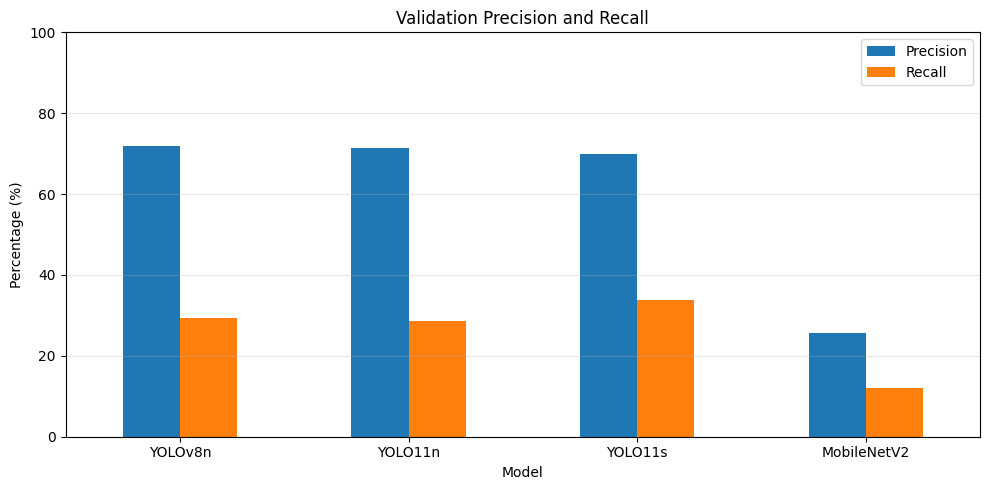

Saved plot: /workspace/ITS_Project/results/model_comparison/precision_recall_comparison.png


In [13]:
# CELL 7: Plot precision and recall for available models

plot_df = metrics_df.copy()

for column in ["Precision", "Recall"]:
    plot_df[column] = pd.to_numeric(plot_df[column], errors="coerce") * 100

plot_df = plot_df.dropna(subset=["Precision", "Recall"])

if plot_df.empty:
    print("No models have both precision and recall available.")
else:
    ax = plot_df.set_index("Model")[["Precision", "Recall"]].plot(
        kind="bar", figsize=(10, 5)
    )
    ax.set_ylabel("Percentage (%)")
    ax.set_title("Validation Precision and Recall")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()

    figure_path = COMPARISON_DIR / "precision_recall_comparison.png"
    plt.savefig(figure_path, dpi=150)
    plt.show()

    print("Saved plot:", figure_path)

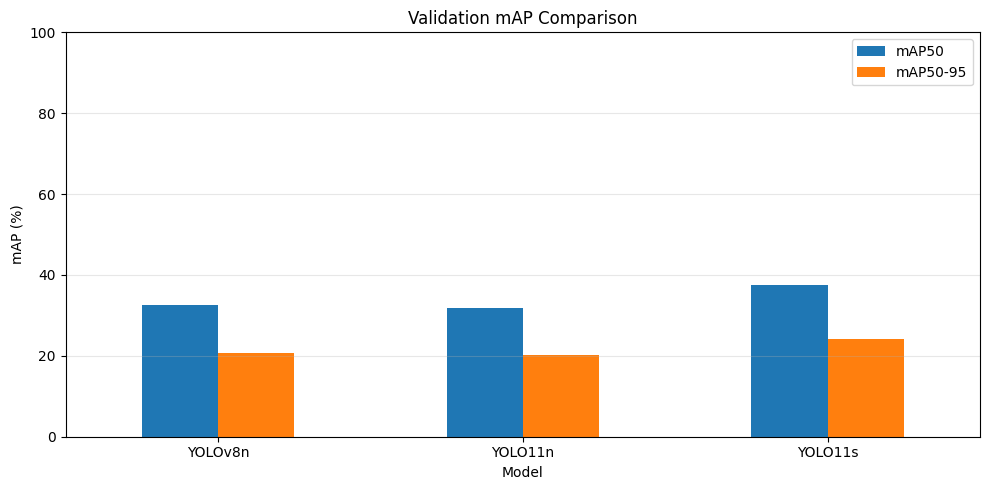

Saved plot: /workspace/ITS_Project/results/model_comparison/map_comparison.png


In [14]:
# CELL 8: Plot mAP@50 and mAP@50–95 for available models

map_df = metrics_df.copy()

for column in ["mAP50", "mAP50-95"]:
    map_df[column] = pd.to_numeric(map_df[column], errors="coerce") * 100

map_df = map_df.dropna(subset=["mAP50", "mAP50-95"])

if map_df.empty:
    print("No comparable mAP metrics are available.")
else:
    ax = map_df.set_index("Model")[["mAP50", "mAP50-95"]].plot(
        kind="bar", figsize=(10, 5)
    )
    ax.set_ylabel("mAP (%)")
    ax.set_title("Validation mAP Comparison")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.3)
    plt.xticks(rotation=0)
    plt.tight_layout()

    figure_path = COMPARISON_DIR / "map_comparison.png"
    plt.savefig(figure_path, dpi=150)
    plt.show()

    print("Saved plot:", figure_path)

In [15]:
# CELL 9: Combine validation metrics and checkpoint sizes

final_df = metrics_df.merge(
    size_df[["Model", "Size (MB)", "Checkpoint available"]],
    on="Model",
    how="left",
)

metric_columns = ["Precision", "Recall", "mAP50", "mAP50-95"]

for column in metric_columns:
    final_df[column] = pd.to_numeric(final_df[column], errors="coerce")

final_df["Best mAP@50 (%)"] = (final_df["mAP50"] * 100).round(2)
final_df["Precision (%)"] = (final_df["Precision"] * 100).round(2)
final_df["Recall (%)"] = (final_df["Recall"] * 100).round(2)
final_df["mAP@50–95 (%)"] = (final_df["mAP50-95"] * 100).round(2)

final_df["Metric status"] = final_df.apply(
    lambda row: (
        "mAP available"
        if pd.notna(row["mAP50"]) and pd.notna(row["mAP50-95"])
        else "Partial metrics" if pd.notna(row["Precision"]) or pd.notna(row["Recall"])
        else "Detection metrics unavailable"
    ),
    axis=1,
)

final_table_path = COMPARISON_DIR / "final_model_comparison.csv"
final_df.to_csv(final_table_path, index=False)

display(final_df[[
    "Model", "Precision (%)", "Recall (%)",
    "Best mAP@50 (%)", "mAP@50–95 (%)",
    "Size (MB)", "Metric status"
]])

print("Saved final comparison table:", final_table_path)

,Model,Precision (%),Recall (%),Best mAP@50 (%),mAP@50–95 (%),Size (MB),Metric status
0,YOLOv8n,71.91,29.37,32.50,20.58,6.20,mAP available
1,YOLO11n,71.40,28.74,31.82,20.24,5.24,mAP available
2,YOLO11s,69.82,33.80,37.60,24.13,18.28,mAP available
3,MobileNetV2,25.62,12.14,NaN,NaN,19.97,Partial metrics


Saved final comparison table: /workspace/ITS_Project/results/model_comparison/final_model_comparison.csv


In [16]:
# CELL 10: Save comparison report as JSON

report_path = COMPARISON_DIR / "comparison_report.json"

report = {
    "project": "Privacy-Preserving Edge AI Framework for Intelligent Transportation",
    "dataset": "IDD Detection",
    "evaluation_split": "validation",
    "models": final_df.replace({np.nan: None}).to_dict(orient="records"),
    "notes": [
        "YOLO metrics come from the saved validation evaluation JSON files.",
        "MobileNetV2 precision and recall are comparable only with caution: they use the custom grid detector and IoU 0.50 matching evaluator.",
        "MobileNetV2 mAP is unavailable because average precision across confidence thresholds has not been implemented.",
        "The test split has no annotations and was not used to calculate accuracy or mAP.",
        "Checkpoint size is the saved file size, not GPU memory usage.",
    ],
}

with open(report_path, "w") as f:
    json.dump(report, f, indent=2, default=str)

print("Saved comparison report:", report_path)
print("Final table:", final_table_path)
print("Checkpoint sizes:", size_path)

Saved comparison report: /workspace/ITS_Project/results/model_comparison/comparison_report.json
Final table: /workspace/ITS_Project/results/model_comparison/final_model_comparison.csv
Checkpoint sizes: /workspace/ITS_Project/results/model_comparison/checkpoint_sizes.csv
